In [3]:
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
import time 
import matplotlib.pyplot as plt

In [6]:
fashion=fetch_openml("Fashion-MNIST",version=1,as_frame=False)
x,y=fashion.data,fashion.target.astype(int)

In [12]:
rng=np.random.RandomState(42)
idx=rng.choice(len(x),6000,replace=False)
x,y=x[idx]/255,y[idx]
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=.2,random_state=42,stratify=y
)


In [17]:
k_values=[1,3,5,7,9,11]
accuracies=[]

from sklearn.metrics import accuracy_score

In [18]:
for k in k_values:
    knn=KNeighborsClassifier(n_neighbors=k)
    start=time.time()
    knn.fit(x_train,y_train)
    y_pred=knn.predict(x_test)
    elapsed=time.time()-start
    acc=accuracy_score(y_test,y_pred)
    accuracies.append(acc)
    print(f"K={k} : Accuracy:{acc:.4f},Time={elapsed:.2f}s")

K=1 : Accuracy:0.8025,Time=0.16s
K=3 : Accuracy:0.8000,Time=0.15s
K=5 : Accuracy:0.8042,Time=0.15s
K=7 : Accuracy:0.8150,Time=0.15s
K=9 : Accuracy:0.8083,Time=0.29s
K=11 : Accuracy:0.8092,Time=0.27s


C:\Users\HP\AppData\Local\Temp\ipykernel_1800\1370141886.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


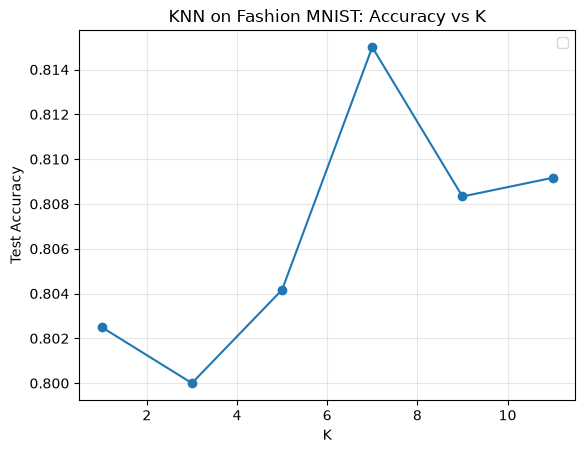

In [21]:
plt.plot(k_values,accuracies,marker="o")
plt.xlabel("K")
plt.ylabel("Test Accuracy")
plt.title("KNN on Fashion MNIST: Accuracy vs K")
plt.grid(alpha=.3)
plt.legend()
plt.show()